# Permanência na UTI — protocolo ampliado de 24 horas (v4)

**88 variáveis no MIMIC; 83 no painel harmonizado com o eICU.**
Sobre o painel original foram acrescentados PAS, AKI por creatinina, SOFA adaptado, arritmias,
ausculta, valvulopatia prévia e registro de cateterismo (v3), mantendo `inputevents` e `outputevents`.
O v4 acrescenta o contexto conhecido até 24h: tipo de UTI, origem antes da UTI, horas entre a
admissão hospitalar e a UTI e tendências (último valor e variação) de creatinina, ureia e lactato.

Para LOS >3,55 dias, o XGBoost obteve AUC **0,758** (IC95% 0,744–0,772) no teste MIMIC;
a MLP, **0,761**. Para >7 dias: **0,781** e **0,776**.
No eICU, o modelo harmonizado congelado obteve **0,688** (XGBoost) e **0,634** (MLP) para
>3,55 dias, e **0,716** e **0,671** para >7 dias.

Os resultados são exploratórios: a partição interna já foi consultada no desenvolvimento.
AKI do modelo principal usa apenas creatinina e o SOFA tem componentes adaptados e ausentes.
O experimento aproximado de Yang aparece separado, com população e janela diferentes.
As tabelas abaixo apresentam IC95%, calibração e contribuição das mudanças.

## 1. Método, fontes e execução

Adultos com IC, ainda na UTI em 24h; óbitos são mantidos. Eventos e disponibilidade
devem ser anteriores a 24h. FEVE preserva a janela −48h/+24h e não possui horário
de liberação de laudo. CID identifica retrospectivamente a coorte; não entra no modelo principal.

Divisão por paciente preservada da análise anterior. Busca de hiperparâmetros em
três partes agrupadas por paciente, exclusivamente no treino MIMIC. Imputação e
escala são ajustadas dentro das partes. O eICU recebe o modelo congelado.
Busca: oito candidatos XGBoost/classificação, quatro MLP e quatro por regressor;
semente 42. O limiar é escolhido no treino. AUC da busca não é validação independente.

Fontes locais: MIMIC-IV 3.1, eICU-CRD 2.0 e medidas estruturadas de Echo 1.0.1.
Código e mapeamentos: [protocolo ampliado](docs/protocolo_ampliado.md).
Artigo: [Yang et al.](https://doi.org/10.1093/eurjcn/zvaf075).

Para refazer a extração, siga o [README](README.md). A execução padrão abaixo lê
os resultados concluídos. Ative `REFAZER_EXPERIMENTOS` apenas para repetir os ajustes.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import roc_curve
from IPython.display import display
from experimentos_24h import ROOT, V3, NOVAS, CONTEXTO, TODAS, TODAS_V3, rodar, diferenca_pareada

REFAZER_EXPERIMENTOS = False
if REFAZER_EXPERIMENTOS:
    rodar('tudo', bootstrap=500)
required = ['completo_ampliado/classificacao.csv','harmonizado/classificacao.csv',
            'ablacoes/comparacao.csv','yang_aproximado/comparacao.csv','auditoria_resumo.json']
missing = [str(ROOT/f) for f in required if not (ROOT/f).exists()]
if missing:
    raise FileNotFoundError('Execute experimentos_24h.py --etapa tudo. Faltam: '+', '.join(missing))
N_COMPLETO=len(TODAS); N_HARM=int(pd.read_csv(ROOT/'harmonizacao.csv').incluida.sum())
print(f'Preditores: {N_COMPLETO} no MIMIC ({len(TODAS_V3)} do v3 + {len(CONTEXTO)} de contexto); {N_HARM} harmonizados.')
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
CORES = {'xgboost':'#2166ac','rede_neural':'#b35806'}
full = pd.read_csv(ROOT/'completo_ampliado/classificacao.csv')
harm = pd.read_csv(ROOT/'harmonizado/classificacao.csv')
quality = pd.read_csv(ROOT/'qualidade_variaveis.csv')
audit = json.loads((ROOT/'auditoria_resumo.json').read_text())
display(pd.DataFrame({b:audit[b] for b in ['mimic','eicu']}).T)
print('Unidade: uma estadia de UTI. Preditores:', audit['n_preditores_completo'], '/', audit['n_preditores_harmonizado'])


Preditores: 88 no MIMIC (70 do v3 + 18 de contexto); 83 harmonizados.


,estadias,pacientes,hospitais,prevalencia_355,prevalencia_7
mimic,21549.0,14655.0,1.0,0.406979,0.173001
eicu,13537.0,11169.0,198.0,0.403265,0.156165


Unidade: uma estadia de UTI. Preditores: 88 / 83


## 2. Cobertura e harmonização

Sem valor registrado não significa normal. Os indicadores de tratamento representam
evidência encontrada; os totais de volume/urina ficam ausentes quando não há medida.
FEVE, tipo de admissão, dose total de furosemida e NT-proBNP/indicador não integram
o modelo externo. Ausculta e troponina T são particularmente esparsas no eICU.
Valvulopatia histórica e arritmias têm fontes diferentes nas duas bases.

Contexto: tipo de UTI e origem são indicadores (categoria ausente = todos zero). No MIMIC,
a origem é a última unidade em `transfers` antes da UTI; no eICU, `unitadmitsource`.
Unidades combinadas CCU-CTICU do eICU foram agrupadas como coronarianas.
A variação de laboratório exige ao menos duas medidas nas primeiras 24h.

,variavel,motivo
11,feve,Nenhum valor recuperado em pelo menos uma base...
23,nt_probnp_max_24h,Nenhum valor recuperado em pelo menos uma base...
29,furosemida_dose_total_24h,Nenhum valor recuperado em pelo menos uma base...
37,nt_probnp_medido,Sem NT-proBNP equivalente; BNP não é substituto
53,tipo_admissao,Nenhum valor recuperado em pelo menos uma base...


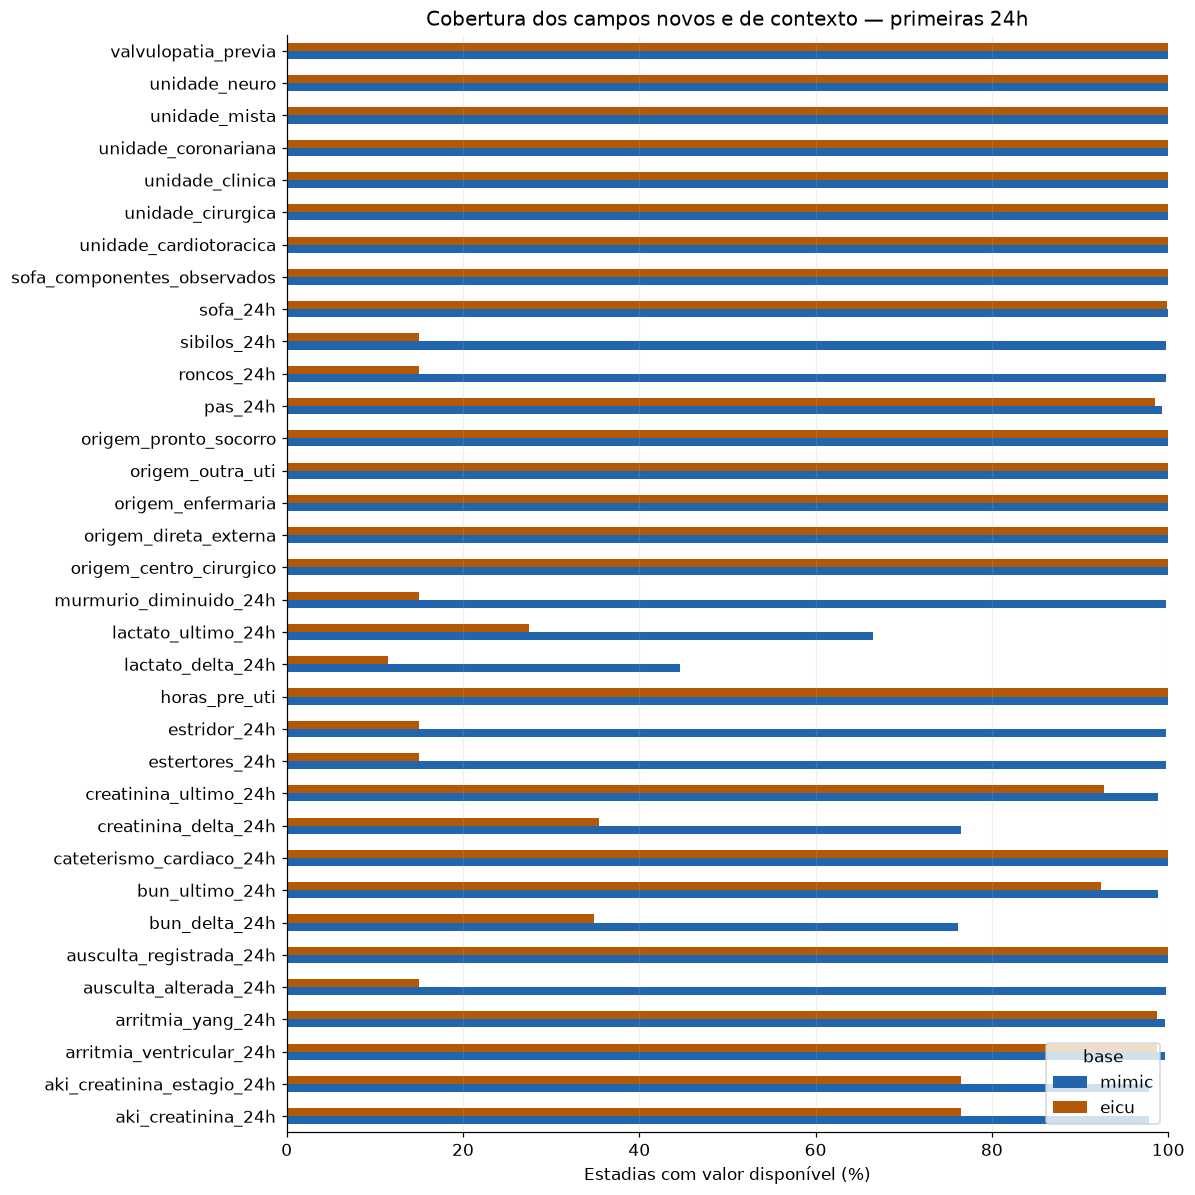

,base,variavel,n,fracao_ausente,p1,p50,p99
30,mimic,volume_infundido_24h,21549,0.142,36.786,1458.505,10110.702
31,mimic,diurese_total_24h,21549,0.058,10.000,1405.000,5880.700
55,mimic,aki_creatinina_estagio_24h,21549,0.022,0.000,0.000,3.000
57,mimic,sofa_24h,21549,0.000,0.000,6.000,17.000
58,mimic,sofa_componentes_observados,21549,0.000,3.000,5.000,6.000
118,eicu,volume_infundido_24h,13537,0.535,20.873,1140.000,7172.540
119,eicu,diurese_total_24h,13537,0.325,0.000,1404.000,6600.000
143,eicu,aki_creatinina_estagio_24h,13537,0.235,0.000,0.000,3.000
145,eicu,sofa_24h,13537,0.001,0.000,4.000,13.000
146,eicu,sofa_componentes_observados,13537,0.000,2.000,4.000,6.000


In [2]:
mapping = pd.read_csv(ROOT/'harmonizacao.csv')
display(mapping.loc[~mapping.incluida,['variavel','motivo']])
coverage = quality[quality.variavel.isin(NOVAS+CONTEXTO)].pivot(index='variavel',columns='base',values='fracao_ausente')
coverage = (1-coverage)*100
ax=coverage[['mimic','eicu']].plot.barh(figsize=(11,11),color=['#2166ac','#b35806'])
ax.set(xlim=(0,100),xlabel='Estadias com valor disponível (%)',ylabel='',title='Cobertura dos campos novos e de contexto — primeiras 24h')
ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()
display(quality[quality.variavel.isin(['sofa_24h','sofa_componentes_observados','aki_creatinina_estagio_24h',
    'volume_infundido_24h','diurese_total_24h'])][['base','variavel','n','fracao_ausente','p1','p50','p99']].round(3))


## 3. Classificação ajustada: MIMIC e eICU

O painel de 88 campos tem avaliação interna. O modelo de 83 campos foi treinado
separadamente no MIMIC e validado no eICU. AUC mede discriminação; Brier mede erro
das probabilidades. As barras de erro são IC95% por bootstrap de pacientes.

,perfil,base,modelo,corte,n,auc,auc_ic95_inf,auc_ic95_sup,auc_pr,brier,vpp,vpn
0,completo_ampliado,mimic,xgboost,3.55,4426,0.758,0.744,0.772,0.676,0.193,0.594,0.770
1,completo_ampliado,mimic,rede_neural,3.55,4426,0.761,0.748,0.775,0.678,0.192,0.601,0.773
2,completo_ampliado,mimic,xgboost,7.00,4426,0.781,0.763,0.800,0.419,0.117,0.316,0.926
3,completo_ampliado,mimic,rede_neural,7.00,4426,0.776,0.758,0.795,0.409,0.117,0.317,0.923
4,harmonizado,mimic,xgboost,3.55,4426,0.757,0.743,0.771,0.676,0.193,0.606,0.760
5,harmonizado,eicu,xgboost,3.55,13537,0.688,0.679,0.697,0.588,0.225,0.608,0.677
6,harmonizado,mimic,rede_neural,3.55,4426,0.758,0.744,0.772,0.668,0.193,0.602,0.776
7,harmonizado,eicu,rede_neural,3.55,13537,0.634,0.624,0.643,0.548,0.230,0.474,0.698
8,harmonizado,mimic,xgboost,7.00,4426,0.778,0.760,0.795,0.415,0.118,0.338,0.922
9,harmonizado,eicu,xgboost,7.00,13537,0.716,0.705,0.728,0.310,0.126,0.343,0.880


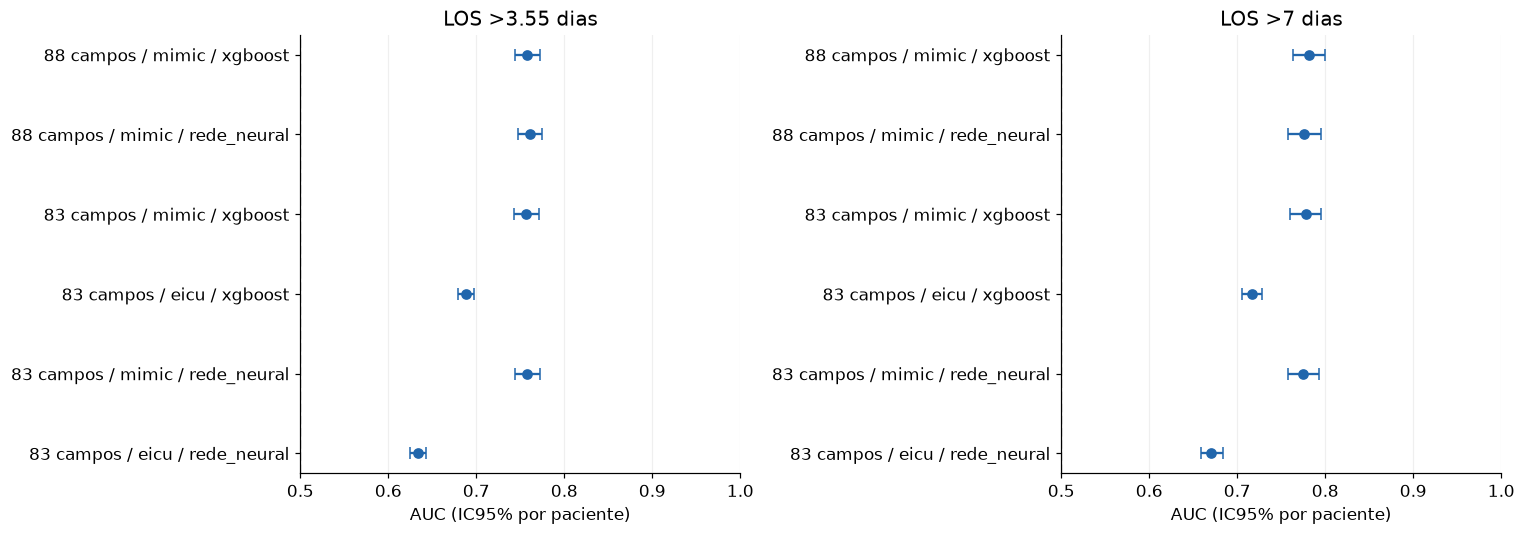

In [3]:
metrics=pd.concat([full,harm],ignore_index=True)
display(metrics[['perfil','base','modelo','corte','n','auc','auc_ic95_inf','auc_ic95_sup','auc_pr','brier','vpp','vpn']].round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,cut in zip(axes,[3.55,7.]):
    tab=metrics[metrics.corte.eq(cut)].copy()
    tab['rotulo']=tab.perfil.replace({'completo_ampliado':f'{N_COMPLETO} campos','harmonizado':f'{N_HARM} campos'})+' / '+tab.base+' / '+tab.modelo
    pos=np.arange(len(tab))
    ax.errorbar(tab.auc,pos,xerr=[tab.auc-tab.auc_ic95_inf,tab.auc_ic95_sup-tab.auc],fmt='o',color='#2166ac',capsize=4)
    ax.set_yticks(pos,tab.rotulo);ax.invert_yaxis()
    ax.set(xlim=(.5,1),xlabel='AUC (IC95% por paciente)',title=f'LOS >{cut:g} dias')
    ax.axvline(.5,color='gray',ls='--');ax.grid(axis='x',alpha=.2)
plt.tight_layout();plt.show()


## 4. Antes e depois

Mesma partição interna e mesmas estadias. As linhas "54 → v4" e "13 → v4" comparam com
o primeiro protocolo e combinam revisão da extração, novas variáveis e ajuste de
hiperparâmetros; não atribuem todo ganho a um único fator. As linhas "v3 → v4" isolam
melhor o contexto: o v3 é o mesmo painel sem os preditores de contexto, com busca própria.
A ablação mais abaixo isola o acréscimo de variáveis sob o mesmo ajuste XGBoost.

In [4]:
oldroot=Path('artefatos_protocolo_24h')
rows=[]
for profile,newfolder,oldbase,base in [
    ('MIMIC: 54 → v4',ROOT/'completo_ampliado/interno',oldroot/'completo/interno','mimic'),
    ('eICU: 13 → v4',ROOT/'harmonizado/externo',oldroot/'comum/externo','eicu'),
    ('MIMIC: v3 → v4 (contexto)',ROOT/'completo_ampliado/interno',V3/'completo_ampliado/interno','mimic'),
    ('eICU: v3 → v4 (contexto)',ROOT/'harmonizado/externo',V3/'harmonizado/externo','eicu')]:
    for cut in [3.55,7.]:
        for model in ['xgboost','rede_neural']:
            key=f'{model}_{cut:g}d'
            a=pd.read_csv(newfolder/key/'previsoes.csv')
            b=pd.read_csv(oldbase/key/'previsoes.csv')
            old=pd.read_csv(oldbase/key/'metricas.csv').iloc[0]
            new=pd.read_csv(newfolder/key/'metricas.csv').iloc[0]
            delta=diferenca_pareada(a,b,bootstrap=500)
            rows.append(dict(comparacao=profile,modelo=model,corte=cut,auc_antes=old.auc,auc_agora=new.auc,
                delta=delta['delta_completo_menos_variante'],ic95_inf=delta['ic95_inf'],ic95_sup=delta['ic95_sup']))
before_after=pd.DataFrame(rows)
before_after.to_csv(ROOT/'antes_depois_pareado.csv',index=False)
display(before_after.round(4))

,comparacao,modelo,corte,auc_antes,auc_agora,delta,ic95_inf,ic95_sup
0,MIMIC: 54 → v4,xgboost,3.55,0.7310,0.7576,0.0266,0.0182,0.0354
1,MIMIC: 54 → v4,rede_neural,3.55,0.7299,0.7605,0.0306,0.0202,0.0409
2,MIMIC: 54 → v4,xgboost,7.00,0.7579,0.7814,0.0235,0.0131,0.0344
3,MIMIC: 54 → v4,rede_neural,7.00,0.7321,0.7759,0.0437,0.0305,0.0568
4,eICU: 13 → v4,xgboost,3.55,0.6201,0.6882,0.0681,0.0586,0.0769
5,eICU: 13 → v4,rede_neural,3.55,0.6137,0.6338,0.0201,0.0091,0.0306
6,eICU: 13 → v4,xgboost,7.00,0.6371,0.7164,0.0793,0.0661,0.0914
7,eICU: 13 → v4,rede_neural,7.00,0.6216,0.6705,0.0489,0.0358,0.0625
8,MIMIC: v3 → v4 (contexto),xgboost,3.55,0.7412,0.7576,0.0164,0.0103,0.0237
9,MIMIC: v3 → v4 (contexto),rede_neural,3.55,0.7480,0.7605,0.0125,0.0056,0.0203


## 5. MLP versus XGBoost

Delta = AUC MLP − AUC XGBoost. O mesmo sorteio de pacientes é usado para os dois.
Intervalo contendo zero indica diferença incerta nesta amostra, não equivalência comprovada.


In [5]:
paired=[]
for profile,place in [('completo_ampliado','interno'),('harmonizado','interno'),('harmonizado','externo')]:
    paired.append(pd.read_csv(ROOT/profile/place/'rede_neural_vs_xgboost.csv').assign(perfil=profile,avaliacao=place))
display(pd.concat(paired,ignore_index=True).round(4))
params=[]
for folder in (ROOT/'completo_ampliado/buscas').iterdir():
    fit=joblib.load(folder/'ajuste.joblib')
    model=fit['modelo'].named_steps['modelo']
    model=getattr(model,'regressor_',model)
    params.append({'modelo_alvo':folder.name,'score_cv':fit['score_cv'],
        'epocas_modelo_final':getattr(model,'n_iter_',np.nan),
        'limite_epocas':getattr(model,'max_iter',np.nan),
        'parametros':json.dumps(fit['params'],ensure_ascii=False)})
display(pd.DataFrame(params))


,corte,auc_rede,auc_xgboost,delta_auc,delta_ic95_inf,delta_ic95_sup,perfil,avaliacao
0,3.55,0.7605,0.7576,0.0029,-0.0046,0.0100,completo_ampliado,interno
1,7.00,0.7759,0.7814,-0.0055,-0.0140,0.0024,completo_ampliado,interno
2,3.55,0.7577,0.7569,0.0007,-0.0075,0.0084,harmonizado,interno
3,7.00,0.7744,0.7777,-0.0033,-0.0105,0.0050,harmonizado,interno
4,3.55,0.6338,0.6882,-0.0544,-0.0618,-0.0459,harmonizado,externo
5,7.00,0.6705,0.7164,-0.0459,-0.0558,-0.0359,harmonizado,externo


,modelo_alvo,score_cv,epocas_modelo_final,limite_epocas,parametros
0,rede_neural_3.55d,0.752708,92.0,200.0,"{""modelo__learning_rate_init"": 0.0005, ""modelo..."
1,rede_neural_7d,0.773487,100.0,200.0,"{""modelo__learning_rate_init"": 0.0005, ""modelo..."
2,regressao_rede_neural,-2.703280,124.0,200.0,"{""modelo__regressor__learning_rate_init"": 0.00..."
3,regressao_xgboost,-2.692547,NaN,NaN,"{""modelo__regressor__subsample"": 0.8, ""modelo_..."
4,xgboost_3.55d,0.754338,NaN,NaN,"{""modelo__subsample"": 0.8, ""modelo__reg_lambda..."
5,xgboost_7d,0.769574,NaN,NaN,"{""modelo__subsample"": 0.8, ""modelo__reg_lambda..."


## 6. Curvas ROC

Teste interno do painel completo e validação externa do harmonizado.
Os números são calculados nas mesmas previsões usadas nas tabelas de métricas.


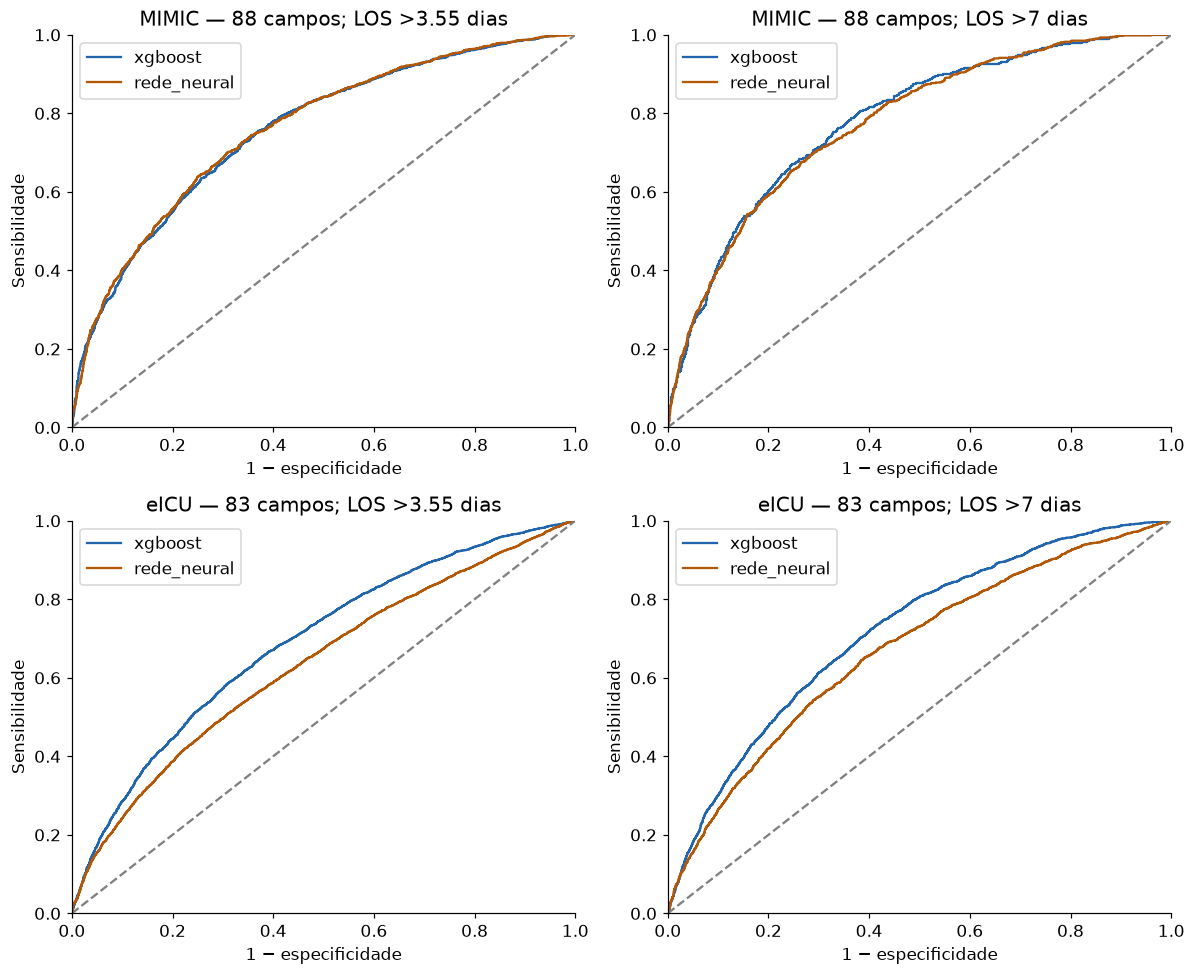

In [6]:
fig,axes=plt.subplots(2,2,figsize=(11,9))
for row,(profile,place,title) in enumerate([('completo_ampliado','interno',f'MIMIC — {N_COMPLETO} campos'),('harmonizado','externo',f'eICU — {N_HARM} campos')]):
    for col,cut in enumerate([3.55,7.]):
        ax=axes[row,col]
        for model in CORES:
            pred=pd.read_csv(ROOT/profile/place/f'{model}_{cut:g}d/previsoes.csv')
            fpr,tpr,_=roc_curve(pred.alvo,pred.probabilidade)
            ax.plot(fpr,tpr,label=model,color=CORES[model])
        ax.plot([0,1],[0,1],'--',color='gray');ax.legend()
        ax.set(xlabel='1 − especificidade',ylabel='Sensibilidade',title=f'{title}; LOS >{cut:g} dias',xlim=(0,1),ylim=(0,1))
plt.tight_layout();plt.show()


## 7. Calibração e DCA

A diagonal representa probabilidades calibradas. A DCA compara benefício líquido
retrospectivo por limiar; não comprova benefício assistencial. Para legibilidade,
mostra-se a DCA até 0,8, com eixo vertical de −0,1 a 0,5; CSVs mantêm a faixa completa.


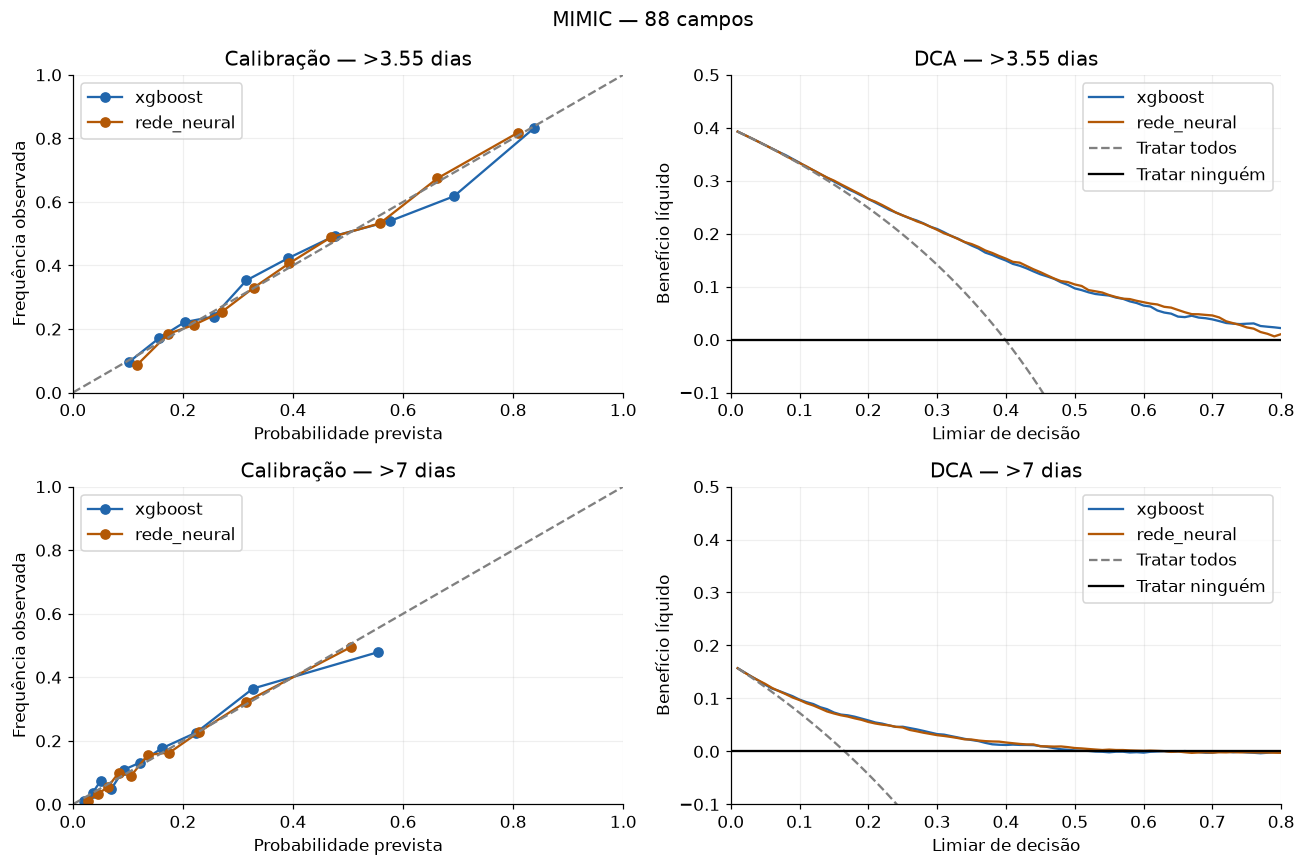

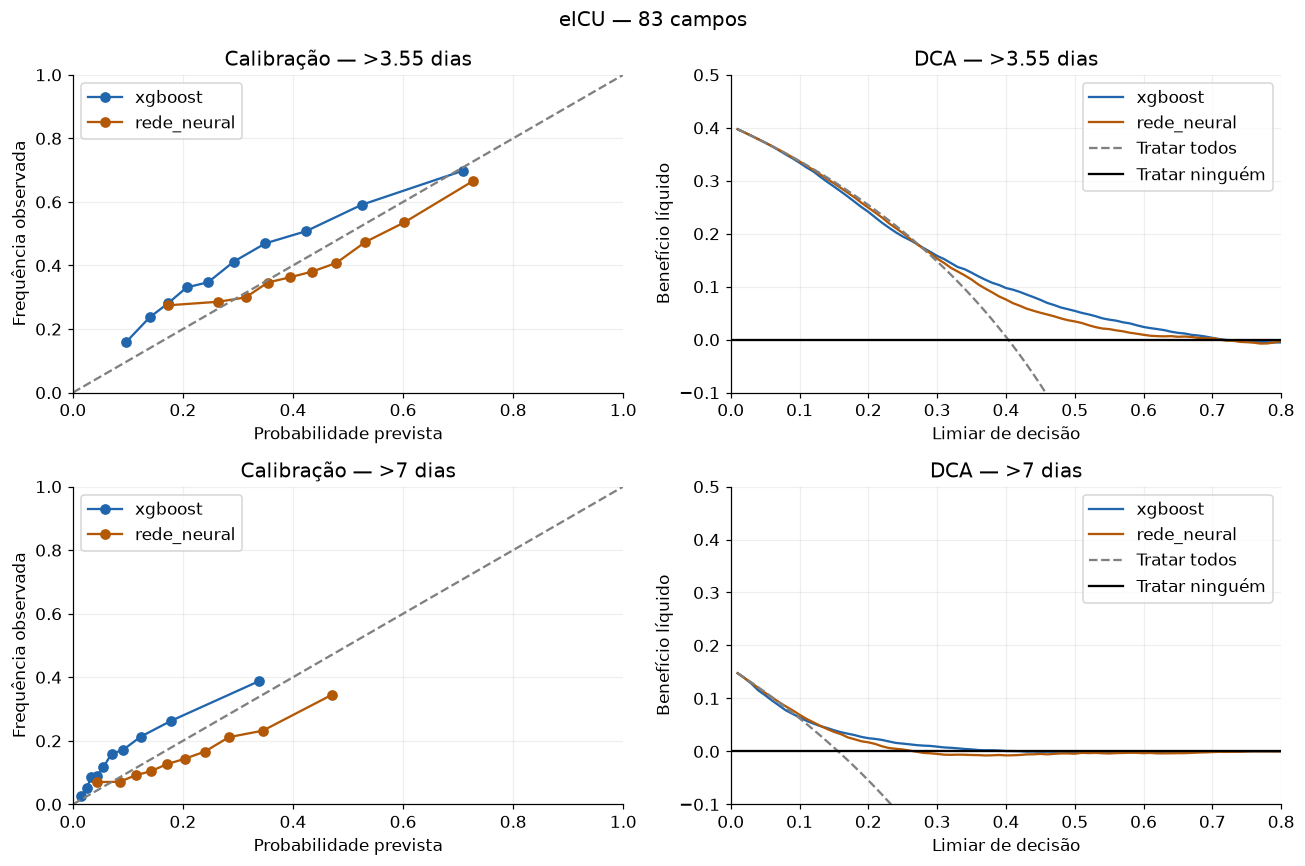

In [7]:
for profile,place,title in [('completo_ampliado','interno',f'MIMIC — {N_COMPLETO} campos'),('harmonizado','externo',f'eICU — {N_HARM} campos')]:
    fig,axes=plt.subplots(2,2,figsize=(12,8))
    for row,cut in enumerate([3.55,7.]):
        for model in CORES:
            folder=ROOT/profile/place/f'{model}_{cut:g}d'
            cal=pd.read_csv(folder/'calibracao.csv');dc=pd.read_csv(folder/'dca.csv')
            axes[row,0].plot(cal.probabilidade_media,cal.frequencia_observada,'o-',label=model,color=CORES[model])
            axes[row,1].plot(dc.limiar,dc.modelo,label=model,color=CORES[model])
        axes[row,0].plot([0,1],[0,1],'--',color='gray')
        axes[row,0].set(xlim=(0,1),ylim=(0,1),xlabel='Probabilidade prevista',ylabel='Frequência observada',title=f'Calibração — >{cut:g} dias')
        axes[row,1].plot(dc.limiar,dc.tratar_todos,'--',color='gray',label='Tratar todos')
        axes[row,1].axhline(0,color='black',label='Tratar ninguém')
        axes[row,1].set(xlim=(0,.8),ylim=(-.1,.5),xlabel='Limiar de decisão',ylabel='Benefício líquido',title=f'DCA — >{cut:g} dias')
        for ax in axes[row]: ax.legend();ax.grid(alpha=.2)
    fig.suptitle(title);plt.tight_layout();plt.show()


## 8. SHAP: quais variáveis o XGBoost utilizou

Importância absoluta média em até 500 estadias do teste, semente 42. Não informa
direção do efeito, causalidade ou utilidade clínica isolada. Variáveis correlacionadas
podem repartir importância. Campos do v3 aparecem em laranja e os de contexto (v4), em verde.

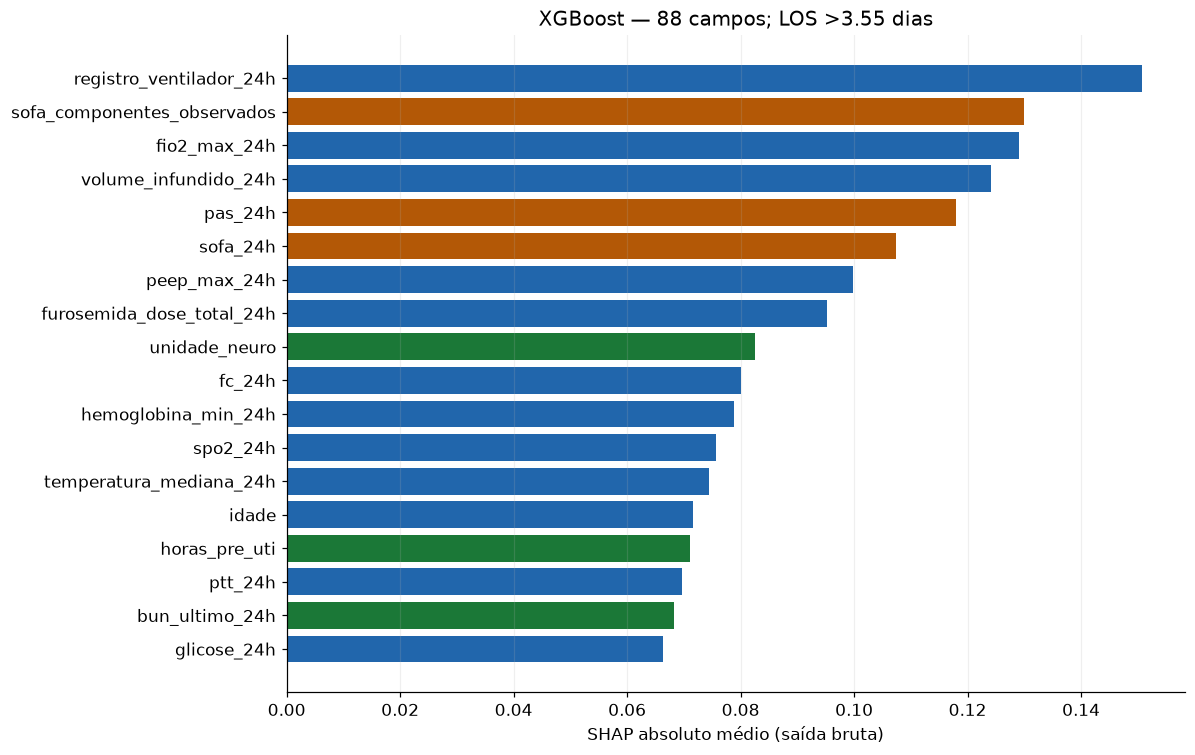

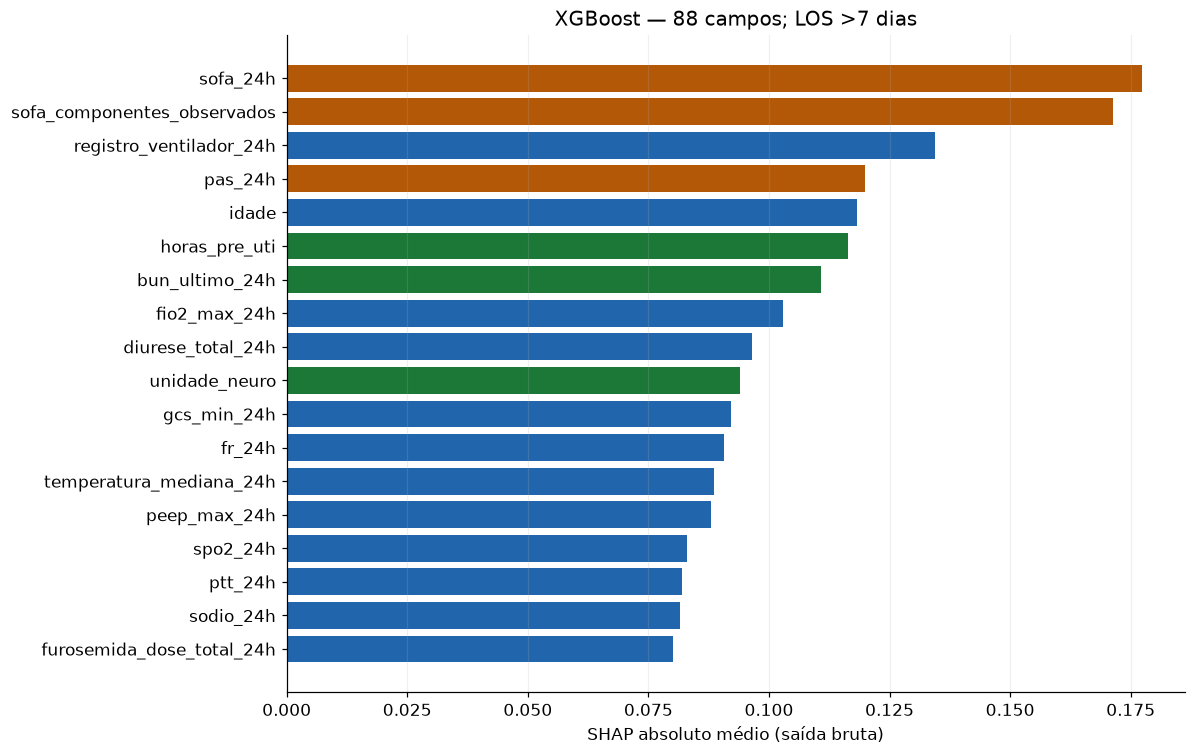

In [8]:
for cut in [3.55,7.]:
    sh=pd.read_csv(ROOT/'completo_ampliado/interno'/f'xgboost_{cut:g}d/shap.csv')
    sh['nome']=sh.variavel.str.replace('num__','',regex=False).str.replace('cat__','',regex=False)
    top=sh.head(18).sort_values('shap_absoluto_medio')
    fig,ax=plt.subplots(figsize=(11,7))
    ax.barh(top.nome,top.shap_absoluto_medio,color=['#1b7837' if n in CONTEXTO else ('#b35806' if n in NOVAS else '#2166ac') for n in top.nome])
    ax.set(xlabel='SHAP absoluto médio (saída bruta)',title=f'XGBoost — {N_COMPLETO} campos; LOS >{cut:g} dias')
    ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()


## 9. Ablações: o que cada alteração acrescentou

Seis variantes XGBoost comparadas ao modelo completo, mantendo os hiperparâmetros
selecionados no painel completo. "Sem novas variáveis" volta ao painel original de 54 campos;
"sem contexto" volta ao painel do v3. Filtro de ausência e imputação são aprendidos no treino
de cada parte. "Sem eventos" remove também SOFA e sua contagem, porque SOFA incorpora urina e
vasopressores. A coluna CV orienta a escolha exploratória; o teste não é usado para selecionar variante.

,variante,corte,auc_cv,auc,auc_ic95_inf,auc_ic95_sup,brier,n_preditores_transformados
0,completo_ampliado,3.55,0.7543,0.7576,0.7436,0.7721,0.1931,95
1,sem_novas_variaveis,3.55,0.7306,0.7360,0.7219,0.7510,0.2003,61
2,sem_contexto,3.55,0.7341,0.7412,0.7270,0.7573,0.1986,77
3,sem_entradas_saidas,3.55,0.7455,0.7440,0.7305,0.7597,0.1983,73
4,sem_mais_30pct_ausencia,3.55,0.7476,0.7506,0.7369,0.7652,0.1957,84
5,indicadores_de_ausencia,3.55,0.7577,0.7604,0.7467,0.7759,0.1920,145
6,laboratorios_maximos,3.55,0.7537,0.7550,0.7408,0.7695,0.1944,95
7,completo_ampliado,7.00,0.7695,0.7814,0.7634,0.7998,0.1173,95
8,sem_novas_variaveis,7.00,0.7450,0.7568,0.7380,0.7777,0.1191,61
9,sem_contexto,7.00,0.7504,0.7576,0.7389,0.7776,0.1199,77


,variante,corte,delta_completo_menos_variante,ic95_inf,ic95_sup
0,sem_novas_variaveis,3.55,0.0216,0.0146,0.0291
1,sem_contexto,3.55,0.0164,0.0103,0.0237
2,sem_entradas_saidas,3.55,0.0136,0.0068,0.0201
3,sem_mais_30pct_ausencia,3.55,0.0070,0.0007,0.0132
4,indicadores_de_ausencia,3.55,-0.0028,-0.0072,0.0015
5,laboratorios_maximos,3.55,0.0026,-0.0020,0.0070
6,sem_novas_variaveis,7.00,0.0246,0.0146,0.0339
7,sem_contexto,7.00,0.0238,0.0153,0.0325
8,sem_entradas_saidas,7.00,0.0123,0.0039,0.0209
9,sem_mais_30pct_ausencia,7.00,0.0127,0.0059,0.0196


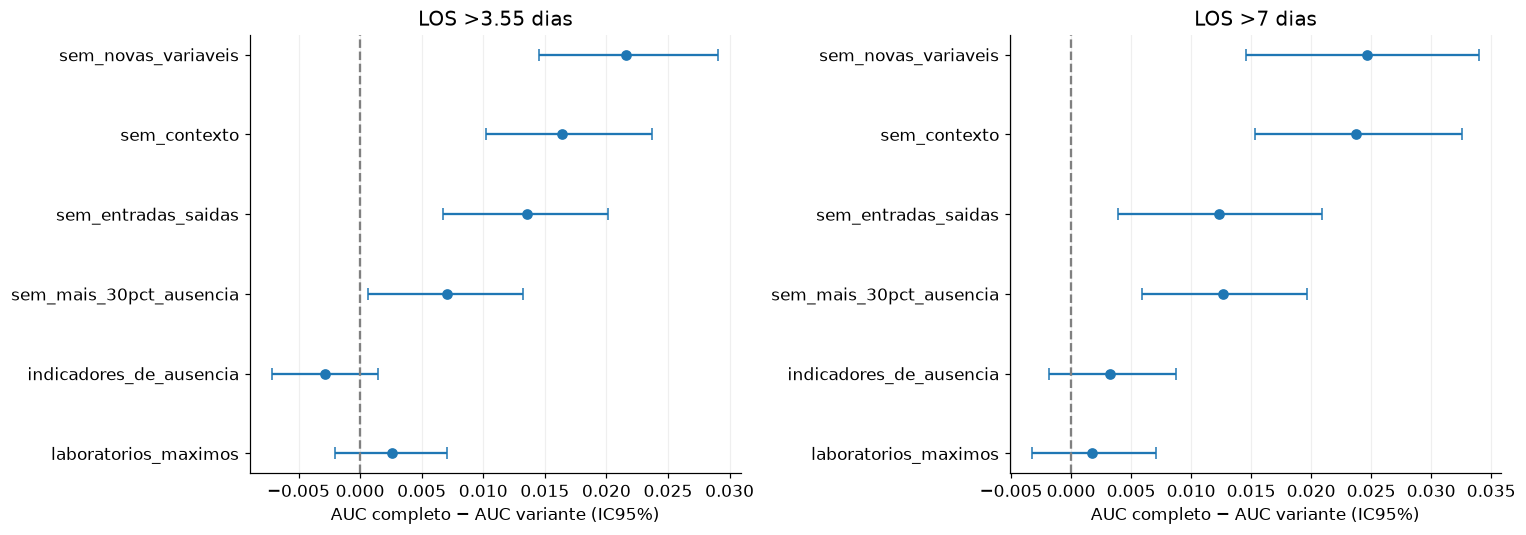

,corte,variante,auc_cv,auc
0,7.00,completo_ampliado,0.7695,0.7814
1,3.55,indicadores_de_ausencia,0.7577,0.7604


In [9]:
ab=pd.read_csv(ROOT/'ablacoes/comparacao.csv')
display(ab[['variante','corte','auc_cv','auc','auc_ic95_inf','auc_ic95_sup','brier','n_preditores_transformados']].round(4))
delta=pd.read_csv(ROOT/'ablacoes/diferencas_pareadas.csv')
display(delta.round(4))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,cut in zip(axes,[3.55,7.]):
    d=delta[delta.corte.eq(cut)]
    ax.errorbar(d.delta_completo_menos_variante,np.arange(len(d)),
        xerr=[d.delta_completo_menos_variante-d.ic95_inf,d.ic95_sup-d.delta_completo_menos_variante],fmt='o',capsize=4)
    ax.set_yticks(np.arange(len(d)),d.variante);ax.invert_yaxis();ax.axvline(0,color='gray',ls='--')
    ax.set(xlabel='AUC completo − AUC variante (IC95%)',title=f'LOS >{cut:g} dias')
    ax.grid(axis='x',alpha=.2)
plt.tight_layout();plt.show()
display(pd.read_csv(ROOT/'ablacoes/escolha_por_cv.csv')[['corte','variante','auc_cv','auc']].round(4))


## 10. Previsão do número de dias

Regressão de LOS observado, transformado com log1p no treino. MAE/RMSE em dias;
R² pode ser negativo. São modelos diferentes dos classificadores e incluem saídas por morte.


,perfil,base,modelo,n,mae,rmse,r2
0,completo_ampliado,mimic,xgboost,4426,2.504,4.953,0.151
1,completo_ampliado,mimic,rede_neural,4426,2.519,4.933,0.158
2,harmonizado,mimic,xgboost,4426,2.511,4.953,0.151
3,harmonizado,eicu,xgboost,13537,2.667,4.994,0.058
4,harmonizado,mimic,rede_neural,4426,2.516,4.990,0.139
5,harmonizado,eicu,rede_neural,13537,3.086,5.160,-0.006


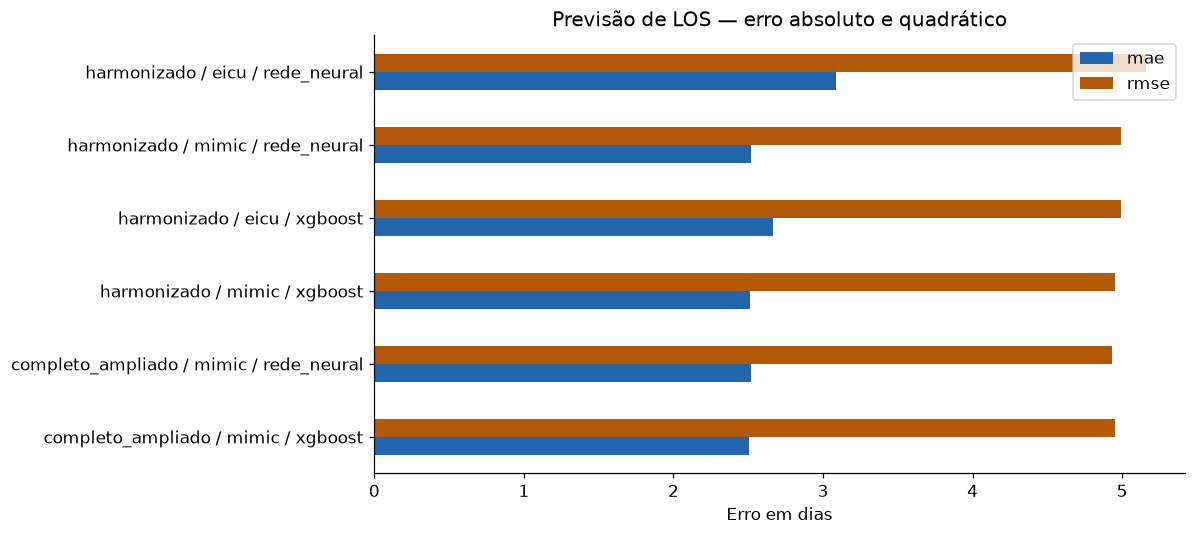

In [10]:
reg=pd.concat([pd.read_csv(ROOT/profile/'regressao.csv').assign(perfil=profile)
    for profile in ['completo_ampliado','harmonizado']],ignore_index=True)
display(reg[['perfil','base','modelo','n','mae','rmse','r2']].round(3))
tab=reg.copy();tab['rotulo']=tab.perfil+' / '+tab.base+' / '+tab.modelo
ax=tab.set_index('rotulo')[['mae','rmse']].plot.barh(figsize=(11,5),color=['#2166ac','#b35806'])
ax.set(xlabel='Erro em dias',ylabel='',title='Previsão de LOS — erro absoluto e quadrático')
plt.tight_layout();plt.show()


## 11. Yang aproximado — experimento separado

IC principal, sobreviventes hospitalares, primeira UTI da internação, incluindo
estadias ≤24h. Dez conceitos importantes, com diagnósticos retrospectivos e tratamentos
até 48h. Esta análise não é reprodução exata do artigo nem modelo prospectivo de 24h.
Não deve substituir o resultado principal ou ser escolhida apenas por apresentar AUC maior.

No artigo, **0,922 é Random Forest no treino**; XGBoost teve 0,861 interna e 0,815
externa. A comparação direta é limitada por versão, população, extração e protocolo.

A tabela abaixo é a versão padrão (IC em `seq_num=1`, AKI por creatinina). As análises de
reprodução ficam em `experimentos_v3/yang_aproximado_*`: com IC nas posições 1–2 (tamanho e
prevalência próximos ao artigo) e AKI KDIGO em 48h, o XGBoost chegou a 0,716 no MIMIC e
0,684 no eICU. Revisar arritmia, ausculta e valvulopatia mudou a AUC em menos de 0,01.

In [11]:
yang=pd.read_csv(ROOT/'yang_aproximado/comparacao.csv')
lim=json.loads((ROOT/'yang_aproximado/limites.json').read_text(encoding='utf-8'))
print(f"Coorte aproximada: {lim['n_mimic']} estadias MIMIC e {lim['n_eicu']} eICU.")
display(yang[['base','modelo','n','prevalencia','auc','auc_ic95_inf','auc_ic95_sup','brier']].round(3))
for line in lim['limites']: print('•',line)


Coorte aproximada: 1492 estadias MIMIC e 3744 eICU.


,base,modelo,n,prevalencia,auc,auc_ic95_inf,auc_ic95_sup,brier
0,mimic,xgboost,296,0.287,0.720,0.651,0.782,0.179
1,eicu,xgboost,3744,0.251,0.660,0.642,0.681,0.183
2,mimic,rede_neural,296,0.287,0.741,0.673,0.808,0.181
3,eicu,rede_neural,3744,0.251,0.676,0.658,0.696,0.177


• Aproximação de 10 preditores importantes; não reprodução exata dos 41 candidatos ou nove algoritmos
• MIMIC 3.1, não 2.2
• AKI somente critério de creatinina; SOFA adaptado, com cobertura explícita
• Diagnósticos retrospectivos podem não estar disponíveis em 24h; não utilizar como modelo prospectivo
• Diurético e cateterismo até 48h; evidência registrada varia entre as bases
• Split por paciente preservado; não selecionar sobreviventes na população principal


## 12. Sensibilidade por óbito, hospitais e convergência

A sensibilidade separa o mesmo modelo por desfecho hospitalar. A auditoria por
hospital mostra cobertura de fontes; métricas de hospitais pequenos são descritivas.
Avisos de convergência da MLP não são ocultados.


In [12]:
sensitivity=[]
for cut in [3.55,7.]:
    sensitivity.append(pd.read_csv(ROOT/'completo_ampliado/interno'/f'xgboost_{cut:g}d/sensibilidade_obitos.csv').assign(corte=cut))
display(pd.concat(sensitivity)[['corte','grupo','n','auc','brier','vpp','vpn']].round(3))
hosp=pd.read_csv(ROOT/'cobertura_por_hospital.csv')
cols=[c for c in hosp if c.startswith('cobertura_')]
display(hosp[hosp.base.eq('eicu')][cols].agg(['min','median','max']).T.round(3))
warnings=[]
for f in ROOT.glob('**/avisos.csv'):
    w=pd.read_csv(f)
    if not w.empty:
        warnings.append({'busca':str(f.parent.relative_to(ROOT)),'n_avisos':len(w),'exemplo':w.aviso.iloc[0]})
display(pd.DataFrame(warnings))
print('Resultados individuais e modelos permanecem locais, excluídos do Git.')


,corte,grupo,n,auc,brier,vpp,vpn
0,3.55,sobreviventes,3770,0.765,0.185,0.593,0.783
1,3.55,obitos_hospitalares,656,0.645,0.241,0.597,0.603
0,7.00,sobreviventes,3770,0.798,0.102,0.306,0.936
1,7.00,obitos_hospitalares,656,0.638,0.207,0.345,0.824


,min,median,max
cobertura_aki_creatinina_estagio_24h,0.000,0.823,1.00
cobertura_sofa_24h,0.839,1.000,1.00
cobertura_ausculta_alterada_24h,0.000,0.000,1.00
cobertura_diurese_total_24h,0.000,0.746,1.00
cobertura_volume_infundido_24h,0.000,0.130,1.00
cobertura_troponina_t_max_24h,0.000,0.000,0.75


,busca,n_avisos,exemplo
0,yang_aproximado\buscas\rede_neural,15,Stochastic Optimizer: Maximum iterations (200)...
1,harmonizado\buscas\rede_neural_3.55d,3,Stochastic Optimizer: Maximum iterations (200)...
2,harmonizado\buscas\rede_neural_7d,3,Stochastic Optimizer: Maximum iterations (200)...
3,harmonizado\buscas\regressao_rede_neural,3,Stochastic Optimizer: Maximum iterations (200)...
4,completo_ampliado\buscas\rede_neural_3.55d,7,Stochastic Optimizer: Maximum iterations (200)...
5,completo_ampliado\buscas\rede_neural_7d,3,Stochastic Optimizer: Maximum iterations (200)...
6,completo_ampliado\buscas\regressao_rede_neural,3,Stochastic Optimizer: Maximum iterations (200)...


Resultados individuais e modelos permanecem locais, excluídos do Git.


## Leitura dos resultados

Considere conjuntamente AUC, ICs pareados, calibração, cobertura e estabilidade externa.
As ablações medem a contribuição neste ajuste e nesta amostra; não provam que uma
variável é universalmente útil ou inútil. SHAP alto no artigo não garante o mesmo
ranking aqui. O eICU testa transferência entre bases, incluindo diferenças de registro.

Os arquivos de evidência estão em `artefatos_protocolo_24h/experimentos_v4/`. O v3 (sem
contexto) e as análises de população, AKI e reprodução de Yang ficam em `experimentos_v3/`;
os resultados de 54/13 campos permanecem em `completo/` e `comum/`.

**Resultados desta execução (24/11/2026):** o contexto melhorou todos os modelos em relação
ao v3, com ICs pareados acima de zero: +0,016 (>3,55 d) e +0,024 (>7 d) no XGBoost interno;
+0,022 e +0,030 no XGBoost externo (eICU). Na ablação, retirar o contexto custou 0,016 e
0,024 de AUC, e retirar todas as novas variáveis, 0,022 e 0,025. Internamente, as diferenças
entre MLP e XGBoost incluem zero; no eICU, o XGBoost foi melhor nos dois cortes (cerca de
0,05). Os intervalos exploratórios não foram corrigidos por múltiplas comparações.

O registro de ventilação e a quantidade de componentes observados do SOFA estão entre as
variáveis de maior SHAP. Isso sugere que o modelo usa também o processo de medição/registro,
além dos valores clínicos; não significa que medir mais cause internação prolongada. Entre os
preditores de contexto, horas pré-UTI, ureia final e UTI neurológica aparecem no topo para >7 dias.
Ausculta tem cobertura muito menor no eICU, o que limita a transferência dos modelos.

Como referência no eICU, o APACHE IVa (LOS previsto) teve AUC 0,669 e 0,690 nas estadias com
escore (82%); o modelo harmonizado do v3 ficou igual a ele (diferenças pareadas incluindo zero).
O APACHE foi desenvolvido em UTIs americanas semelhantes ao eICU; não é validação externa dele.

O benchmark aproximado de Yang não recuperou o desempenho publicado e não deve ser
apresentado como reprodução do artigo.